In [178]:
import sys
from typing import List, Tuple
import pickle as pkl

import matplotlib.pyplot as plt; plt.rcParams.update({"font.family": "serif"})
import numpy as np
import scipy as sp

import openfermion as of
from openfermionpyscf import run_pyscf

import numpy as np
import openfermion as of

import cirq
import qiskit
import qiskit.qasm2
import quimb.tensor as qtn

sys.path.append("..")
from tensor_network_common import pauli_sum_to_mpo

In [179]:
# Problem to use.
problem: str = "product"  # Options: "hchain", "hubbard", "product", "reactant"

# For Hubbard Hamiltonian.
xdim: int = 4
ydim: int = 3

# For Hydrogen chains.
natoms_list: List[int] = [3, 4, 5]  # Numbers of H atoms in the (linear) chains to study.

hamiltonian_threshold: float = 0.02 # Drop terms in the Hamiltonian with coefficients smaller than this threshold.

# Initial state parameters.
seed: int = 1
alpha: float = 10.0  # The initial state is |ground state> + |random state> / alpha (random state projected to the right particle number).

# Krylov parameters.
subspace_dimension: int = 20  # The dimension of the Krylov subspace (must be even; the subspace uses powers -d/2..d/2).
threshold: float = 1e-4 # 1e-4  # -np.inf  # -1e-4  # Set to -np.inf to disable thresholding.
dt_scale: float = 1.0  # Time step is dt = dt_scale * pi / ||H||_1, with ||H||_1 the sum of |coefficients| (non-identity terms).

# Shot-noise parameters.
nshots_min_exp: float = 2.0  # Shots per estimate are swept over 10^min .. 10^max.
nshots_max_exp: float = 11.0
nshots_per_decade: int = 4
reps: int = 100  # Noise realizations per shot count.
chemical_accuracy: float = 1.6e-3  # Hartree (1 kcal/mol = 1.594 mHa).
noise_threshold_factor: float = 10.0  # For noisy solves, S-threshold = max(threshold, factor * std of S elements). A factor of 1 gave O(1 Ha) errors for H3+.

# Simulation parameters.
max_mpo_bond: int = 128  # Maximum bond dimension for MPO's.
max_mps_bond: int = 256  # Maximum bond dimension for MPS's.

In [180]:
def fill_h_and_s_matrices(
    vectors: List[np.ndarray] | List[np.ndarray],
    mpo: qtn.MatrixProductOperator | np.ndarray,
    verbose: bool = False,
) -> Tuple[np.ndarray, np.ndarray]:
    tensor_algebra = isinstance(mpo, qtn.MatrixProductOperator)

    dim = len(vectors)
    h = np.zeros((dim, dim), dtype=np.complex128)
    s = np.zeros((dim, dim), dtype=np.complex128)

    for i in range(dim):
        for j in range(i, dim):
            if verbose:
                print(f"A_{i}{j}", end=" ")

            if tensor_algebra:
                hij = vectors[i].H @ mpo.apply(vectors[j])
            else:
                hij = vectors[i].conj().T @ mpo @ vectors[j]

            h[i, j] = hij
            if i != j:
                h[j, i] = np.conjugate(hij)

            if tensor_algebra:
                sij = vectors[i].H @ vectors[j]
            else:
                sij = vectors[i].conj().T @ vectors[j]
            s[i, j] = sij
            if i != j:
                s[j, i] = np.conjugate(sij)
    return h, s

# Based on https://quantum.cloud.ibm.com/docs/en/tutorials/krylov-quantum-diagonalization.
# and Algorithm 1.1 of https://arxiv.org/abs/2110.07492.
def solve_regularized_gen_eig(
    h: np.ndarray,
    s: np.ndarray,
    threshold: float = -np.inf,
) -> float:
    s_vals, s_vecs = sp.linalg.eigh(s)
    s_vecs = s_vecs.T
    good_vecs = np.array(
        [vec for val, vec in zip(s_vals, s_vecs) if val > threshold]
    )
    h_reg = good_vecs.conj() @ h @ good_vecs.T
    s_reg = good_vecs.conj() @ s @ good_vecs.T
    return sp.linalg.eigh(h_reg, s_reg)[0][0]

In [181]:
def cirq_pauli_sum_to_qiskit_pauli_op(
    pauli_sum: cirq.PauliSum, qubits: List[cirq.Qid]
) -> qiskit.quantum_info.SparsePauliOp:
    """Returns a qiskit.SparsePauliOp representation of the cirq.PauliSum.

    qubits[i] is mapped to Qiskit qubit i. Qiskit labels are little-endian (the rightmost
    character acts on qubit 0), so the label string is reversed after building it in qubit order.
    """
    cirq_pauli_to_str = {cirq.X: "X", cirq.Y: "Y", cirq.Z: "Z"}

    terms = []
    coeffs = []
    for term in pauli_sum:
        string = ""
        for qubit in qubits:
            if qubit not in term:
                string += "I"
            else:
                string += cirq_pauli_to_str[term[qubit]]
        terms.append(string[::-1])
        assert np.isclose(term.coefficient.imag, 0.0, atol=1e-7)
        coeffs.append(term.coefficient.real)
    return qiskit.quantum_info.SparsePauliOp(terms, coeffs)

In [182]:
def number_projector_mpo(nqubits: int, nparticles: int) -> qtn.MatrixProductOperator:
    """MPO projecting onto computational basis states with Hamming weight nparticles.

    With the Jordan-Wigner transform (OpenFermion convention |1> = occupied), this is the
    projector onto the nparticles-electron sector. The bond index counts particles so far."""
    D = nparticles + 1
    W = np.zeros((D, D, 2, 2))
    for c in range(D):
        for b in range(2):
            if c + b < D:
                W[c, c + b, b, b] = 1.0
    arrays = []
    for i in range(nqubits):
        if i == 0:
            arrays.append(W[0])  # (r, u, d)
        elif i == nqubits - 1:
            arrays.append(W[:, nparticles])  # (l, u, d)
        else:
            arrays.append(W)  # (l, r, u, d)
    return qtn.MatrixProductOperator(arrays)


def one_norm(qubit_operator: of.QubitOperator) -> float:
    """Sum of |coefficients| over non-identity terms (an upper bound on the spectral range / 2)."""
    return sum(abs(c) for term, c in qubit_operator.terms.items() if term != ())

In [183]:
def unitary_h_and_s_variance(
    vectors: List[qtn.MatrixProductState] | List[np.ndarray], ks: List[int], mpo: qtn.MatrixProductOperator | np.ndarray,
    subspace_dimension: int,
) -> Tuple[np.ndarray, np.ndarray]:
    """Single-shot variances of the real and imaginary parts of the matrix elements H_kj and S_kj.

    Array index a corresponds to the Krylov power k = a - subspace_dimension // 2.

    With the IBM (Hadamard-test) technique, H_kj ~= <psi0|H U^m|psi0> with m = j - k is estimated
    from <X otimes H> (real part) and <Y otimes H> (imaginary part) using controlled-U^m.
    Since (X otimes H)^2 = (Y otimes H)^2 = I otimes H^2, the single-shot variance is
        <I otimes H^2> - <X otimes H>^2,  with  <I otimes H^2> = 1/2 (<psi0|H^2|psi0> + <psi0|U_m^dag H^2 U_m|psi0>).
    For S_kj set H = I, giving <I otimes I> = 1, so Var = 1 - (Re or Im S)^2.
    The m = 0 elements need no ancilla: H_kk = <psi0|H|psi0> is real with variance
    <H^2> - <H>^2, and S_kk = 1 is known exactly (zero variance).

    The variances only depend on m, consistent with all elements of the same m being estimated
    from the same circuit.

    NOTE: this treats H as a single observable measured in one shot. In practice H is measured
    as several groups of commuting Pauli terms, which gives a larger variance, so shot counts
    from this model are a lower bound.

    Arguments:
    vectors - The vectors U^k|psi0> for all k in ks (must include k = -d..d).
    ks - The power of the unitary generating each vector, e.g. k=2 for U^2|psi_0>.
    Negative values mean backwards time evolution, i.e. powers of U^dagger.
    mpo - Hamiltonian operator.
    subspace_dimension - d; matrices are (d+1) x (d+1).

    Returns:
    h_var - The re/im of h_var[a, b] is the single-shot variance of the re/im of H_ab.
    s_var - The re/im of s_var[a, b] is the single-shot variance of the re/im of S_ab."""
    assert len(ks) == len(vectors)
    assert subspace_dimension % 2 == 0, "subspace_dimension must be even."

    tensor_algebra = isinstance(mpo, qtn.MatrixProductOperator)

    def apply_h(v):
        return mpo.apply(v) if tensor_algebra else mpo @ v

    def inner(u, v):
        return u.H @ v if tensor_algebra else u.conj().T @ v

    psi0 = vectors[ks.index(0)]
    h_psi0 = apply_h(psi0)
    psi0_h2_psi0 = inner(h_psi0, h_psi0).real

    # Toeplitz quantities for each offset m = j - k.
    toeplitz = {}
    for m in range(0, subspace_dimension + 1):
        psi_m = vectors[ks.index(m)]
        h_psi_m = apply_h(psi_m)
        h2_m = inner(h_psi_m, h_psi_m).real
        hm = inner(h_psi0, psi_m)  # <psi0|H U^m|psi0>
        sm = inner(psi0, psi_m)  # <psi0|U^m|psi0>
        exp_h_sq = 0.5 * (psi0_h2_psi0 + h2_m)
        if m == 0:
            hv = complex(psi0_h2_psi0 - hm.real ** 2, 0.0)
            sv = 0.0 + 0.0j
        else:
            hv = (exp_h_sq - hm.real ** 2) + 1.0j * (exp_h_sq - hm.imag ** 2)
            sv = (1.0 - sm.real ** 2) + 1.0j * (1.0 - sm.imag ** 2)
        toeplitz[m] = (hv, sv)

    dim = subspace_dimension + 1
    h_var = np.zeros((dim, dim), dtype=np.complex128)
    s_var = np.zeros((dim, dim), dtype=np.complex128)
    for a in range(dim):
        for b in range(dim):
            hv, sv = toeplitz[abs(b - a)]
            h_var[a, b] = hv
            s_var[a, b] = sv
    return h_var, s_var

In [184]:
def _nonnegative(x: float, what: str) -> float:
    if x < 0.0:
        if abs(x) <= 1e-8:
            return 0.0
        raise ValueError(f"Negative variance for {what}: {x}")
    return x


def perturb_h_s_with_noise(
    h: np.ndarray, s: np.ndarray, h_var: np.ndarray, s_var: np.ndarray, shots: int,
    rng: np.random.Generator,
) -> Tuple[np.ndarray, np.ndarray]:
    """Add shot noise to H and S, keeping both Hermitian.

    shots is the number of shots per estimate (each Re/Im part of each distinct Toeplitz offset
    m = j - k). Elements with the same m come from the same circuit, so they share one noise draw.
    S_kk = 1 is known exactly and the diagonal of H is real."""
    assert h.shape == h_var.shape, f"{h.shape} != {h_var.shape}"
    assert s.shape == s_var.shape, f"{s.shape} != {s_var.shape}"
    dim = h.shape[0]

    # Standard normal draws for (Re H, Im H, Re S, Im S) for each offset m.
    z = rng.standard_normal((dim, 4))

    noisy_h = np.zeros(h.shape, dtype=complex)
    noisy_s = np.zeros(s.shape, dtype=complex)
    for a in range(dim):
        for b in range(a, dim):
            m = b - a
            std_re_h = np.sqrt(_nonnegative(h_var[a, b].real, f"Re H[{a},{b}]") / shots)
            std_im_h = np.sqrt(_nonnegative(h_var[a, b].imag, f"Im H[{a},{b}]") / shots)
            std_re_s = np.sqrt(_nonnegative(s_var[a, b].real, f"Re S[{a},{b}]") / shots)
            std_im_s = np.sqrt(_nonnegative(s_var[a, b].imag, f"Im S[{a},{b}]") / shots)
            if m == 0:
                noisy_h[a, a] = h[a, a].real + std_re_h * z[m, 0]
                noisy_s[a, a] = s[a, a].real
            else:
                noisy_h[a, b] = h[a, b] + std_re_h * z[m, 0] + 1.0j * std_im_h * z[m, 1]
                noisy_s[a, b] = s[a, b] + std_re_s * z[m, 2] + 1.0j * std_im_s * z[m, 3]
                noisy_h[b, a] = np.conjugate(noisy_h[a, b])
                noisy_s[b, a] = np.conjugate(noisy_s[a, b])

    assert not np.any(np.isnan(noisy_h))
    assert not np.any(np.isnan(noisy_s))
    return noisy_h, noisy_s

In [185]:
def hchain_matrices(natoms: int, subspace_dimension: int, ntrotter: int=1):
    assert subspace_dimension % 2 == 0, "subspace_dimension must be even."
    bond_distance = 1.0
    geometry = [("H", (0, 0, i * bond_distance)) for i in range(natoms)]
    molecule = of.MolecularData(geometry, basis="sto-3g", multiplicity=1, charge=natoms % 2)

    molecule = run_pyscf(molecule, run_scf=True, run_mp2=True, verbose=True)
    nelectrons = molecule.n_electrons
    nqubits = molecule.n_qubits
    qubits = cirq.LineQubit.range(nqubits)

    hamiltonian = of.get_fermion_operator(molecule.get_molecular_hamiltonian())
    hamiltonian = of.jordan_wigner(hamiltonian)
    if hamiltonian_threshold is not None:
        hamiltonian.compress(hamiltonian_threshold)
    nterms = len(hamiltonian.terms)

    hamiltonian_cirq = of.qubit_operator_to_pauli_sum(hamiltonian)
    mpo = pauli_sum_to_mpo(hamiltonian_cirq, qubits, max_bond=max_mpo_bond, verbose=False)

    # Get the ground state in the correct particle-number sector. The qubit Hamiltonian acts on all
    # of Fock space, so add a penalty mu (N - N0)^2 for the DMRG. mu > 2 ||H||_1 guarantees that
    # every other sector is pushed above the target sector.
    hamiltonian_norm = one_norm(hamiltonian)
    penalty_weight = 2.0 * hamiltonian_norm + 1.0
    number_op = of.jordan_wigner(of.number_operator(nqubits))
    penalty = penalty_weight * (number_op - nelectrons * of.QubitOperator(())) ** 2
    penalty.compress()
    penalized_cirq = of.qubit_operator_to_pauli_sum(hamiltonian + penalty)
    penalized_mpo = pauli_sum_to_mpo(penalized_cirq, qubits, max_bond=max_mpo_bond, verbose=False)
    # Start from the Hartree-Fock state (lowest nelectrons spin-orbitals occupied) plus a small random
    # component in the same sector. Pure HF is a fixed point of two-site DMRG (the double excitations
    # that lower its energy act on four sites), and a random start can get stuck in a poor state.
    projector = number_projector_mpo(nqubits, nelectrons)
    hf_state = qtn.MPS_computational_state("1" * nelectrons + "0" * (nqubits - nelectrons))
    dmrg_start = projector.apply(qtn.MPS_rand_state(nqubits, bond_dim=4, seed=seed + 1))
    dmrg_start = hf_state + 0.1 * dmrg_start / dmrg_start.norm()
    dmrg_start /= dmrg_start.norm()
    dmrg = qtn.DMRG2(
        penalized_mpo,
        # Starting the bond-dimension schedule at 2 gets stuck in a local minimum (seen for n=3, 4).
        bond_dims=[2 ** i for i in range(4, int(np.log2(max_mps_bond)) + 1)],
        p0=dmrg_start,
    )
    converged = dmrg.solve(verbosity=1, max_sweeps=50)
    if not converged:
        print("WARNING: DMRG did not converge.")

    ground_state = dmrg.state
    ground_state /= ground_state.norm()
    energy_exact = np.real(ground_state.H @ mpo.apply(ground_state))
    print(f"Ground state energy in N={nelectrons} sector: {energy_exact}")
    if nqubits <= 14:  # Cross-check against exact diagonalization in the particle-number sector.
        h_sparse = of.get_sparse_operator(hamiltonian, n_qubits=nqubits)
        occupations = np.array([bin(i).count("1") for i in range(2 ** nqubits)])
        sector = np.where(occupations == nelectrons)[0]
        energy_ed = np.linalg.eigvalsh(h_sparse[sector][:, sector].toarray())[0]
        print(f"Exact diagonalization energy: {energy_ed}")
        assert np.isclose(energy_exact, energy_ed, atol=1e-6), "DMRG did not find the sector ground state."

    sector_weight = np.real(ground_state.H @ projector.apply(ground_state))
    print(f"Ground state weight in N={nelectrons} sector: {sector_weight}")

    # Random perturbation, projected onto the same particle-number sector.
    random_state = projector.apply(qtn.MPS_rand_state(mpo.L, bond_dim=2, seed=seed))
    random_state /= random_state.norm()
    bvec = ground_state + random_state / alpha
    bvec /= bvec.norm()

    # Time step from the 1-norm of H (upper bound on the spectral norm), which scales
    # polynomially with system size (the Frobenius norm mpo.norm() scales like 2^(n/2)).
    dt = dt_scale * np.pi / hamiltonian_norm
    print(f"||H||_1 = {hamiltonian_norm}, dt = {dt}")

    hamiltonian_qiskit = cirq_pauli_sum_to_qiskit_pauli_op(hamiltonian_cirq, qubits)
    trotter_operation = qiskit.circuit.library.PauliEvolutionGate(
        hamiltonian_qiskit,
        time=dt,
        synthesis=qiskit.synthesis.LieTrotter(reps=ntrotter)
    )
    trotter_circuit = qiskit.QuantumCircuit(nqubits)
    trotter_circuit.append(trotter_operation, trotter_circuit.qubits)
    trotter_circuit = qiskit.transpile(
        trotter_circuit, basis_gates=["u3", "cx"]
    )  # TODO: Compile to a target backend, e.g. IBM Fez.
    # print("Trotter circuit gate counts:")
    # print(trotter_circuit.count_ops())

    forward = trotter_circuit.copy()
    forward_qasm = qiskit.qasm2.dumps(forward)

    reverse = trotter_circuit.inverse().copy()
    reverse_qasm = qiskit.qasm2.dumps(reverse)

    forward_vectors = [bvec]

    for k in range(subspace_dimension):
        # print("Forward:", k)
        new = qtn.CircuitMPS.from_openqasm2_str(
            forward_qasm, psi0=forward_vectors[-1], progbar=False, max_bond=max_mps_bond,
        ).psi
        forward_vectors.append(new)

    reverse_vectors = [bvec]
    for k in range(subspace_dimension):
        # print("Reverse:", k)
        new = qtn.CircuitMPS.from_openqasm2_str(
            reverse_qasm, psi0=reverse_vectors[-1], progbar=False, max_bond=max_mps_bond,
        ).psi
        reverse_vectors.append(new)

    _ = reverse_vectors.pop(0)
    reverse_vectors = list(reversed(reverse_vectors))

    all_vectors_u_trotter = reverse_vectors + forward_vectors
    ks = list(range(-subspace_dimension, subspace_dimension + 1))

    # Trotterized evolution need not conserve particle number exactly; report the leakage.
    last = forward_vectors[-1]
    leakage = 1.0 - np.real(last.H @ projector.apply(last)) / np.real(last.H @ last)
    print(f"Particle-number leakage after {subspace_dimension} Trotter steps: {leakage:.3e}")

    vectors_u_trotter = []
    for k, vec in zip(ks, all_vectors_u_trotter):
        if (k >= -subspace_dimension // 2) and (k <= subspace_dimension // 2):
            vectors_u_trotter.append(vec)

    h, s = fill_h_and_s_matrices(vectors_u_trotter, mpo, verbose=False)
    h_var, s_var = unitary_h_and_s_variance(all_vectors_u_trotter, ks, mpo, subspace_dimension)
    return h, s, h_var, s_var, energy_exact

In [186]:
def run_natoms(natoms: int, subspace_dimension: int, reps: int=10):
    h, s, h_var, s_var, energy_exact = hchain_matrices(natoms, subspace_dimension, ntrotter=3)
    subspace_energy = solve_regularized_gen_eig(h, s, threshold=threshold)
    print(f"Noiseless Krylov energy: {subspace_energy}, error: {abs(subspace_energy - energy_exact)}")
    rng = np.random.default_rng(seed)
    num = int(round((nshots_max_exp - nshots_min_exp) * nshots_per_decade)) + 1
    nshots = np.logspace(nshots_min_exp, nshots_max_exp, num=num)
    # Distinct estimates: m = 0 (Re H only), and m = 1..d (Re/Im of H and S).
    estimates_per_shot_count = 1 + 4 * subspace_dimension
    max_s_var = max(s_var.real.max(), s_var.imag.max())
    noisy_energies = np.zeros((len(nshots), reps))
    noisy_thresholds = np.zeros(len(nshots))
    for i, shots in enumerate(nshots):
        noisy_threshold = max(threshold, noise_threshold_factor * np.sqrt(max_s_var / shots))
        noisy_thresholds[i] = noisy_threshold
        for r in range(reps):
            noisy_h, noisy_s = perturb_h_s_with_noise(h, s, h_var, s_var, shots, rng)
            noisy_energies[i, r] = solve_regularized_gen_eig(noisy_h, noisy_s, noisy_threshold)
    errs = np.abs(noisy_energies - energy_exact)
    result = {
        "natoms": natoms,
        "energy_exact": energy_exact,
        "h": h,
        "s": s,
        "h_var": h_var,
        "s_var": s_var,
        "nshots": nshots,  # Shots per Re/Im estimate of each distinct Toeplitz element.
        "total_shots": nshots * estimates_per_shot_count,
        "estimates_per_shot_count": estimates_per_shot_count,
        "noisy_energies": noisy_energies,  # Shape (len(nshots), reps).
        "noisy_thresholds": noisy_thresholds,
        "mean_errs": errs.mean(axis=1),
        "std_errs": errs.std(axis=1),
        "subspace_energy": subspace_energy,
        "subspace_error": abs(subspace_energy - energy_exact),
        "params": {
            "subspace_dimension": subspace_dimension,
            "ntrotter": 3,
            "hamiltonian_threshold": hamiltonian_threshold,
            "seed": seed,
            "alpha": alpha,
            "threshold": threshold,
            "dt_scale": dt_scale,
            "noise_threshold_factor": noise_threshold_factor,
            "reps": reps,
            "max_mpo_bond": max_mpo_bond,
            "max_mps_bond": max_mps_bond,
            "bond_distance": 1.0,
            "basis": "sto-3g",
        },
    }
    return result

In [187]:
import os
os.makedirs("data", exist_ok=True)

results = {}
for n in natoms_list:
    print(f"===== natoms = {n} =====")
    results[n] = run_natoms(n, subspace_dimension, reps=reps)
    with open(f"data/results_n{n}.pkl", "wb") as f:
        pkl.dump(results[n], f)

===== natoms = 3 =====
Hartree-Fock energy for H3_sto-3g_singlet_1+ (2 electrons) is -1.1889970389622464.
MP2 energy for H3_sto-3g_singlet_1+ (2 electrons) is -1.2131306955585308.
1, R, max_bond=(13/16), cutoff:1e-08


100%|############################################| 5/5 [00:00<00:00, 827.51it/s]

Energy: (-1.2240626258576448+1.3940237852949622e-14j) ... not converged.
2, R, max_bond=(5/32), cutoff:1e-08



100%|###########################################| 5/5 [00:00<00:00, 1167.68it/s]

Energy: (-1.2240626741880491+1.3401606213658823e-14j) ... converged!
Ground state energy in N=2 sector: -1.224062674188051
Exact diagonalization energy: -1.2240626741885814
Ground state weight in N=2 sector: 0.9999999999999997
||H||_1 = 3.674315211658591, dt = 0.8550144646331728


Particle-number leakage after 20 Trotter steps: 4.552e-15
Noiseless Krylov energy: -1.223720105328161, error: 0.0003425688598899246
===== natoms = 4 =====
Hartree-Fock energy for H4_sto-3g_singlet (4 electrons) is -2.0985459369977173.
MP2 energy for H4_sto-3g_singlet (4 electrons) is -2.1397440121679767.
1, R, max_bond=(21/16), cutoff:1e-08


... (6 outputs left out)

Energy: (-2.361788347961548-2.202500334891333e-13j) ... not converged.
2, R, max_bond=(16/32), cutoff:1e-08



100%|############################################| 9/9 [00:00<00:00, 449.01it/s]

Energy: (-2.3618185223852066-2.2049397897794254e-13j) ... converged!


Ground state energy in N=4 sector: -2.3618185929168973
Exact diagonalization energy: -2.3618188719301547
Ground state weight in N=4 sector: 0.9999999927659498
||H||_1 = 9.257231657408147, dt = 0.3393663213640892
Particle-number leakage after 20 Trotter steps: 2.255e-06
Noiseless Krylov energy: -2.361577578499066, error: 0.00024101441783130895


In [188]:
# Reload saved results (this cell and below can be run without re-running the simulations).
results = {}
for n in natoms_list:
    with open(f"data/results_n{n}.pkl", "rb") as f:
        results[n] = pkl.load(f)

In [189]:
# NOTE: the mean error is dominated by rare spurious eigenvalues far below the exact energy
# (a few % of realizations at intermediate shot counts), so use the median / 95th percentile.
def shots_for_accuracy(nshots: np.ndarray, err_stat: np.ndarray, target: float) -> float:
    """Smallest shot count (log-log interpolated) above which err_stat stays <= target.

    Returns np.inf if the target is not reached at the largest shot count, and np.nan if it is
    already reached at the smallest one (i.e. only an upper bound nshots[0] is known)."""
    ok = err_stat <= target
    if not ok[-1]:
        return np.inf
    # Last index that fails; everything after it succeeds.
    fails = np.where(~ok)[0]
    if len(fails) == 0:
        return np.nan
    i = fails[-1]
    x0, x1 = np.log10(nshots[i]), np.log10(nshots[i + 1])
    y0, y1 = np.log10(err_stat[i]), np.log10(err_stat[i + 1])
    t = (np.log10(target) - y0) / (y1 - y0)
    return 10 ** (x0 + t * (x1 - x0))


summary = []
for n, res in results.items():
    errs = np.abs(res["noisy_energies"] - res["energy_exact"])
    row = {
        "natoms": n,
        "energy_exact": res["energy_exact"],
        "subspace_error": res["subspace_error"],
    }
    for name, stat in [("mean", errs.mean(axis=1)),
                       ("median", np.median(errs, axis=1)),
                       ("p95", np.percentile(errs, 95, axis=1))]:
        shots = shots_for_accuracy(res["nshots"], stat, chemical_accuracy)
        row[f"shots_{name}"] = shots
        row[f"total_shots_{name}"] = shots * res["estimates_per_shot_count"]
    summary.append(row)

print(f"Chemical accuracy target: {chemical_accuracy} Ha. Shots are per Re/Im estimate; total = x (1 + 4d).")
print(f"{'N':>3} {'E_exact':>12} {'Krylov err':>11} {'mean':>10} {'median':>10} {'p95':>10} {'total(p95)':>11}")
for row in summary:
    print(f"{row['natoms']:>3} {row['energy_exact']:>12.6f} {row['subspace_error']:>11.2e} "
          f"{row['shots_mean']:>10.2e} {row['shots_median']:>10.2e} {row['shots_p95']:>10.2e} {row['total_shots_p95']:>11.2e}")

with open("data/chemical_accuracy_summary.pkl", "wb") as f:
    pkl.dump({"chemical_accuracy": chemical_accuracy, "summary": summary}, f)

Chemical accuracy target: 0.0016 Ha. Shots are per Re/Im estimate; total = x (1 + 4d).
  N      E_exact  Krylov err       mean     median        p95  total(p95)
  3    -1.224063    3.43e-04   2.33e+06   2.98e+03   1.57e+06    1.27e+08
  4    -2.168871    5.62e-04   3.89e+09   4.14e+04   5.08e+05    4.11e+07
  5    -2.361819    2.41e-04   1.47e+05   4.69e+04   2.91e+05    2.35e+07


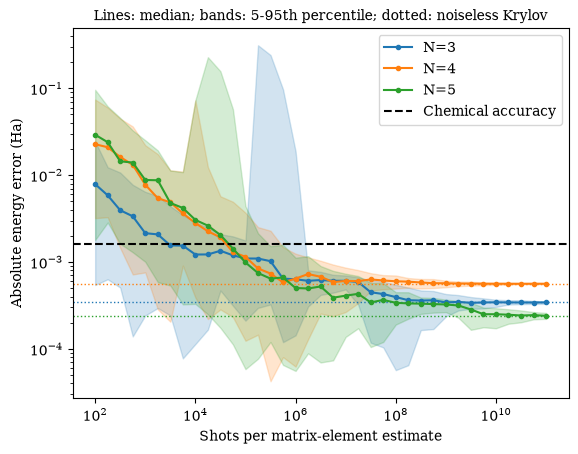

In [190]:
fig, ax = plt.subplots()
for n, res in results.items():
    errs = np.abs(res["noisy_energies"] - res["energy_exact"])
    line, = ax.plot(res["nshots"], np.median(errs, axis=1), "o-", ms=3, label=f"N={n}")
    ax.fill_between(res["nshots"], np.percentile(errs, 5, axis=1), np.percentile(errs, 95, axis=1),
                    color=line.get_color(), alpha=0.2)
    ax.axhline(res["subspace_error"], color=line.get_color(), linestyle=":", lw=1)
ax.axhline(chemical_accuracy, color="black", linestyle="--", label="Chemical accuracy")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Shots per matrix-element estimate")
ax.set_ylabel("Absolute energy error (Ha)")
ax.set_title("Lines: median; bands: 5-95th percentile; dotted: noiseless Krylov", fontsize=10)
ax.legend()
fig.savefig("data/error_vs_shots.pdf", bbox_inches="tight")

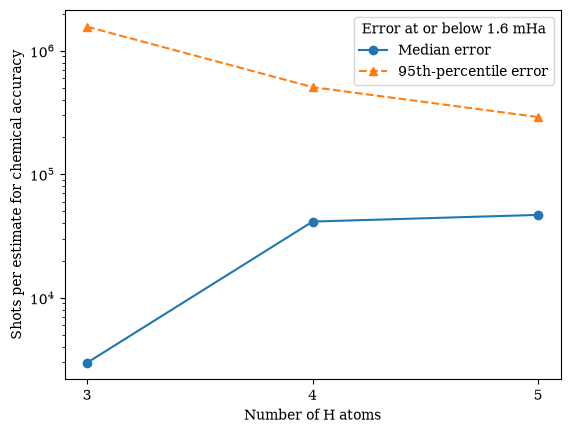

In [191]:
fig, ax = plt.subplots()
ns = [row["natoms"] for row in summary]
ax.plot(ns, [row["shots_median"] for row in summary], "o-", label="Median error")
ax.plot(ns, [row["shots_p95"] for row in summary], "^--", label="95th-percentile error")
ax.set_yscale("log")
ax.set_xticks(ns)
ax.set_xlabel("Number of H atoms")
ax.set_ylabel("Shots per estimate for chemical accuracy")
ax.legend(title="Error at or below 1.6 mHa")
fig.savefig("data/shots_vs_natoms.pdf", bbox_inches="tight")